In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import classification_report, roc_auc_score

# For handling class imbalance
from imblearn.over_sampling import SMOTE

In [3]:
# Load dataset
df = pd.read_csv("creditcard.csv")

In [4]:
# Basic exploration
print("First few rows of the dataset:")
print(df.head())
print("\nDataset Info:")
print(df.info())

First few rows of the dataset:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

 


Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64


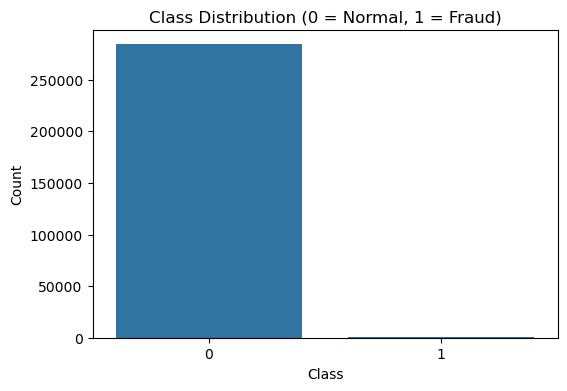

In [5]:
# Class distribution analysis
print("\nClass Distribution:")
print(df['Class'].value_counts())
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df)
plt.title("Class Distribution (0 = Normal, 1 = Fraud)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [6]:
# Check for missing values
missing_values = df.isnull().sum()
print("\nMissing Values per Column:")
print(missing_values[missing_values > 0] if missing_values.any() else "No missing values found.")


Missing Values per Column:
No missing values found.


In [7]:
# Feature scaling for Time and Amount
scaler = StandardScaler()
df['Amount'] = scaler.fit_transform(df[['Amount']])
df['Time'] = scaler.fit_transform(df[['Time']])

In [8]:
# Prepare features and target
X = df.drop('Class', axis=1)
y = df['Class']

# Train-test split with stratification to preserve class ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [9]:
# Model 1: Logistic Regression (No balancing)
print("Model: Logistic Regression (No Class Balancing)")

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)
y_pred_base = log_reg.predict(X_test)

print(classification_report(y_test, y_pred_base))


Model: Logistic Regression (No Class Balancing)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.64      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



In [10]:
# Apply SMOTE to address class imbalance
print("Applying SMOTE Oversampling")

smote = SMOTE(random_state=888)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Class distribution after SMOTE:")
print(pd.Series(y_train_smote).value_counts())

Applying SMOTE Oversampling
Class distribution after SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64


In [11]:
# Model 2: Logistic Regression with SMOTE

print("Model: Logistic Regression (with SMOTE)")

log_reg_smote = LogisticRegression(max_iter=10000)
log_reg_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = log_reg_smote.predict(X_test)

print(classification_report(y_test, y_pred_smote))

Model: Logistic Regression (with SMOTE)
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962



In [12]:
# Model 3: Random Forest with SMOTE

print("Model: Random Forest (with SMOTE)")

rf_clf = RandomForestClassifier(n_estimators=100, random_state=888, n_jobs=-1)
rf_clf.fit(X_train_smote, y_train_smote)
y_pred_rf = rf_clf.predict(X_test)

print(classification_report(y_test, y_pred_rf))

Model: Random Forest (with SMOTE)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.81      0.82        98

    accuracy                           1.00     56962
   macro avg       0.92      0.90      0.91     56962
weighted avg       1.00      1.00      1.00     56962



In [13]:
# Compute ROC-AUC score for probabilistic evaluation
y_prob_rf = rf_clf.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_prob_rf)
print(f"\nROC-AUC Score: {roc_auc:.4f}")


ROC-AUC Score: 0.9688
